# MSBD 566 — Advanced Regression Modeling
## Hands-On Practice Notebook

You just sat through a lecture full of ideas: regularization, GLMs, robust regression, diagnostics. This notebook is where those ideas stop being slides and start being **your own code, run on your own hands, on the same real dataset we've used all semester.**

There's no instructor walking you through this one — so every section below explains *why* we're doing something before showing *how*, the same way class did. Read the markdown, run the code, and actually look at the output before moving to the next cell. If a number surprises you, that's the moment to stop and think, not skip past.

**What we'll rebuild tonight, for real:**

| Step | What you'll do |
|---|---|
| 0 | Set up and load the real diabetes dataset |
| 1 | Build a small, self-contained regression-ready dataset (numeric predictors → `num_medications`) |
| 2 | Fit baseline OLS — simple and multiple — and learn to report it properly |
| 3 | Ridge, Lasso, Elastic Net — and the scaling rule that makes them honest |
| 4 | Reproduce the regularization path plot from class — and play with it yourself |
| 5 | GLMs on real counts and skewed durations — **and the exp(β) rule from tonight's last slide** |
| 6 | Robust regression — protecting a fit from patients who are real, not typos |
| 7 | Diagnostics — the plots that tell you which technique you actually needed |
| 8 | A metrics scoreboard comparing everything you built |
| 9 | Challenge questions — **no AI, these are yours to work through** |

Let's go.


---
## Step 0 — Setup

Same habit as every notebook this semester: fetch the data ourselves so this notebook runs anywhere, and make sure the libraries we need are actually installed before we hit a wall three cells from now.


In [25]:
import os
import urllib.request
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 200)

DATA_URL = "https://archive.ics.uci.edu/static/public/296/diabetes+130-us+hospitals+for+years+1999-2008.zip"
if not os.path.exists("diabetic_data.csv"):
    urllib.request.urlretrieve(DATA_URL, "diabetes_data.zip")
    with zipfile.ZipFile("diabetes_data.zip") as z:
        z.extractall(".")

# scikit-learn guard, same as the class notebooks
try:
    import sklearn
except ModuleNotFoundError:
    %pip install scikit-learn
    import sklearn

data = pd.read_csv("diabetic_data.csv")
data = data.replace('?', np.nan)
print("scikit-learn version:", sklearn.__version__)
print("Raw shape:", data.shape)

scikit-learn version: 1.6.1
Raw shape: (101766, 50)


---
## Step 1 — Build a Small, Self-Contained Regression Dataset

Our semester-long project treats `readmit_30` as the target — but that's a *classification* problem (0 or 1). Tonight's lecture was about **regression**, so we need a genuinely continuous target, and `num_medications` is a perfect, real one: it's a count-like continuous number, it has real spread, and you already have intuition for it from Week 2's EDA.

We'll keep this deliberately small — seven interpretable numeric predictors, no encoding gymnastics — so the *statistics*, not the plumbing, are the star of this notebook. And because leakage doesn't go away just because we're doing regression instead of classification, we split by **patient**, exactly like Week 3.


In [26]:
FEATURES = ['time_in_hospital', 'num_lab_procedures', 'num_procedures',
            'number_outpatient', 'number_emergency', 'number_inpatient',
            'number_diagnoses']
TARGET = 'num_medications'

reg_data = data[FEATURES + [TARGET, 'patient_nbr']].dropna().copy()
print("Regression-ready rows:", reg_data.shape[0])

from sklearn.model_selection import GroupShuffleSplit

X = reg_data[FEATURES]
y = reg_data[TARGET]
groups = reg_data['patient_nbr']

splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(splitter.split(X, y, groups=groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

overlap = set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])
print(f"Train: {X_train.shape} | Test: {X_test.shape} | Patient overlap: {len(overlap)}")
assert len(overlap) == 0

X_train.describe().round(1)

Regression-ready rows: 101766
Train: (81613, 7) | Test: (20153, 7) | Patient overlap: 0


,time_in_hospital,num_lab_procedures,num_procedures,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,81613.0,81613.0,81613.0,81613.0,81613.0,81613.0,81613.0
mean,4.4,43.1,1.3,0.4,0.2,0.6,7.4
std,3.0,19.7,1.7,1.3,1.0,1.3,1.9
min,1.0,1.0,0.0,0.0,0.0,0.0,1.0
25%,2.0,31.0,0.0,0.0,0.0,0.0,6.0
50%,4.0,44.0,1.0,0.0,0.0,0.0,8.0
75%,6.0,57.0,2.0,0.0,0.0,1.0,9.0
max,14.0,132.0,6.0,42.0,76.0,21.0,16.0


---
## Step 2 — Baseline OLS: Simple, Then Multiple

Start where the lecture started: one predictor, then all seven. Watch how the coefficients and the R² change the moment other predictors are added — that's multiple regression's whole value proposition, controlling for everything else at once instead of one variable in isolation.

We'll also introduce the four metrics from class here, on real numbers, so they stop being formulas and start being numbers you've actually produced yourself.


In [27]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def report(name, y_true, y_pred, n_features):
    r2 = r2_score(y_true, y_pred)
    n = len(y_true)
    adj_r2 = 1 - (1 - r2) * (n - 1) / (n - n_features - 1)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    print(f"{name:22s}  R2={r2:.3f}  AdjR2={adj_r2:.3f}  RMSE={rmse:.3f}  MAE={mae:.3f}")
    return {"model": name, "R2": r2, "AdjR2": adj_r2, "RMSE": rmse, "MAE": mae}

scoreboard = []

# --- Simple regression: one predictor ---
simple = LinearRegression().fit(X_train[['num_lab_procedures']], y_train)
pred_simple = simple.predict(X_test[['num_lab_procedures']])
scoreboard.append(report("OLS (1 predictor)", y_test, pred_simple, 1))
print(f"  coefficient on num_lab_procedures: {simple.coef_[0]:.4f}")

# --- Multiple regression: all seven ---
multi = LinearRegression().fit(X_train, y_train)
pred_multi = multi.predict(X_test)
scoreboard.append(report("OLS (7 predictors)", y_test, pred_multi, len(FEATURES)))
print("\nCoefficients, all seven predictors:")
for f, b in zip(FEATURES, multi.coef_):
    print(f"  {f:20s} {b:+.4f}")

OLS (1 predictor)       R2=0.073  AdjR2=0.073  RMSE=7.838  MAE=5.939
  coefficient on num_lab_procedures: 0.1104
OLS (7 predictors)      R2=0.348  AdjR2=0.348  RMSE=6.573  MAE=4.976

Coefficients, all seven predictors:
  time_in_hospital     +0.9135
  num_lab_procedures   +0.0500
  num_procedures       +1.4719
  number_outpatient    +0.2656
  number_emergency     +0.0659
  number_inpatient     +0.1963
  number_diagnoses     +0.5784


**Look at `num_lab_procedures`'s coefficient in both models.** It almost certainly changed between the simple and multiple regression — sometimes substantially. That's not a bug. In the simple model, that one coefficient is silently absorbing the effects of every OTHER predictor it's correlated with. In the multiple model, it's isolated — "holding the other six constant." Neither number is *wrong*; they're answering different questions. This is the everyday, practical meaning of "multiple regression controls for confounders," and you just watched it happen to your own numbers.


---
## Step 3 — Regularization: Ridge, Lasso, Elastic Net (and the Rule You Cannot Skip)

Before we fit anything: **remember the scaling rule from class.** Ridge and Lasso penalize the raw *size* of a coefficient, and our seven features live on wildly different scales — `num_lab_procedures` ranges past 100, `number_emergency` is usually 0. Skip scaling, and the penalty punishes features unfairly based on their units, not their importance.

The cell below proves it to you directly: we'll fit Ridge on the SAME data, once unscaled and once scaled, and look at how differently the coefficients come out.


In [28]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler

# Fit Ridge WITHOUT scaling first — watch number_emergency get crushed
ridge_unscaled = Ridge(alpha=1.0).fit(X_train, y_train)
print("Ridge on UNSCALED data:")
for f, b in zip(FEATURES, ridge_unscaled.coef_):
    print(f"  {f:20s} {b:+.4f}")

# Now scale (fit on train ONLY, then apply to test — same rule as Week 3) and refit
scaler = StandardScaler().fit(X_train)
X_train_s = pd.DataFrame(scaler.transform(X_train), columns=FEATURES, index=X_train.index)
X_test_s  = pd.DataFrame(scaler.transform(X_test),  columns=FEATURES, index=X_test.index)

ridge_scaled = Ridge(alpha=1.0).fit(X_train_s, y_train)
print("\nRidge on SCALED data:")
for f, b in zip(FEATURES, ridge_scaled.coef_):
    print(f"  {f:20s} {b:+.4f}")

Ridge on UNSCALED data:
  time_in_hospital     +0.9135
  num_lab_procedures   +0.0500
  num_procedures       +1.4718
  number_outpatient    +0.2656
  number_emergency     +0.0659
  number_inpatient     +0.1963
  number_diagnoses     +0.5784

Ridge on SCALED data:
  time_in_hospital     +2.7309
  num_lab_procedures   +0.9839
  num_procedures       +2.5113
  number_outpatient    +0.3368
  number_emergency     +0.0636
  number_inpatient     +0.2517
  number_diagnoses     +1.1165



Ridge on SCALED data:
  time_in_hospital     +2.7309
  num_lab_procedures   +0.9839
  num_procedures       +2.5113
  number_outpatient    +0.3368
  number_emergency     +0.0636
  number_inpatient     +0.2517
  number_diagnoses     +1.1165


Notice `number_emergency`'s coefficient on the unscaled fit — tiny, because its raw values rarely exceed single digits, so the penalty barely has to work to shrink it. On the scaled fit, every coefficient is now expressed in "per one standard deviation" terms, and they compete on equal footing. **Always scale before you regularize. No exceptions.**

Now let's fit all three regularized methods properly, on the scaled data, and compare their personalities side by side — Ridge keeps everyone, Lasso cuts the weak, Elastic Net does both.


In [29]:
from sklearn.linear_model import Lasso, ElasticNet

ridge = Ridge(alpha=1.0).fit(X_train_s, y_train)
lasso = Lasso(alpha=0.1).fit(X_train_s, y_train)
enet  = ElasticNet(alpha=0.1, l1_ratio=0.5).fit(X_train_s, y_train)

comparison = pd.DataFrame({
    'OLS':        LinearRegression().fit(X_train_s, y_train).coef_,
    'Ridge':      ridge.coef_,
    'Lasso':      lasso.coef_,
    'ElasticNet': enet.coef_,
}, index=FEATURES).round(3)
print(comparison)

for name, model in [("Ridge", ridge), ("Lasso", lasso), ("ElasticNet", enet)]:
    scoreboard.append(report(name, y_test, model.predict(X_test_s), len(FEATURES)))

                      OLS  Ridge  Lasso  ElasticNet
time_in_hospital    2.731  2.731  2.686       2.603
num_lab_procedures  0.984  0.984  0.913       0.944
num_procedures      2.511  2.511  2.419       2.367
number_outpatient   0.337  0.337  0.251       0.279
number_emergency    0.064  0.064  0.000       0.023
number_inpatient    0.252  0.252  0.182       0.213
number_diagnoses    1.117  1.117  1.062       1.069
Ridge                   R2=0.348  AdjR2=0.348  RMSE=6.573  MAE=4.976
Lasso                   R2=0.347  AdjR2=0.347  RMSE=6.578  MAE=4.980
ElasticNet              R2=0.347  AdjR2=0.347  RMSE=6.578  MAE=4.978


**Read the `Lasso` column specifically.** If any feature shows exactly `0.000`, Lasso decided that predictor wasn't earning its place — real automatic feature selection, on your own data, not a toy example. Compare that to `Ridge`, where every number is nonzero, just smaller than OLS's. That contrast IS the geometry lecture, now sitting in a pandas DataFrame instead of a slide.


---
## Step 4 — Reproduce the Regularization Path Yourself

This is the chart from class — Ridge coefficients bending toward zero, Lasso coefficients hitting it exactly, one at a time. Except this time, YOU generate it, and you can change the `alpha` range and watch the story change.


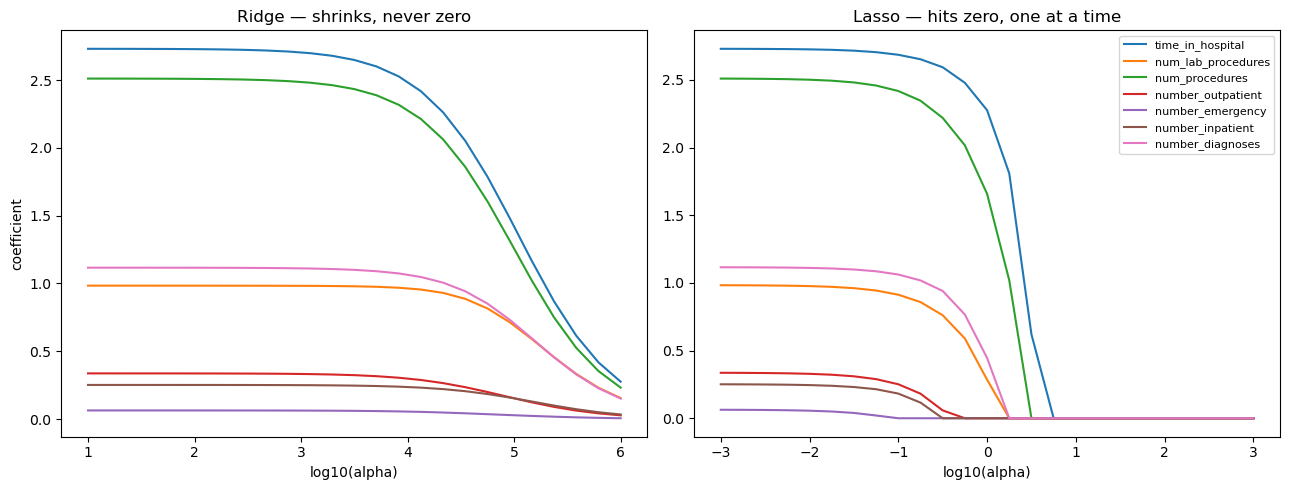

time_in_hospital     hits exactly zero at alpha ≈ 5.623
num_lab_procedures   hits exactly zero at alpha ≈ 1.778
num_procedures       hits exactly zero at alpha ≈ 3.162
number_outpatient    hits exactly zero at alpha ≈ 0.562
number_emergency     hits exactly zero at alpha ≈ 0.100
number_inpatient     hits exactly zero at alpha ≈ 0.316
number_diagnoses     hits exactly zero at alpha ≈ 1.778


In [30]:
alphas_lasso = np.logspace(-3, 3, 25)
alphas_ridge = np.logspace(1, 6, 25)   # Ridge needs a much bigger range at this sample size — see if you can find out why

lasso_path = {f: [] for f in FEATURES}
for a in alphas_lasso:
    m = Lasso(alpha=a, max_iter=20000).fit(X_train_s, y_train)
    for f, b in zip(FEATURES, m.coef_):
        lasso_path[f].append(b)

ridge_path = {f: [] for f in FEATURES}
for a in alphas_ridge:
    m = Ridge(alpha=a).fit(X_train_s, y_train)
    for f, b in zip(FEATURES, m.coef_):
        ridge_path[f].append(b)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for f in FEATURES:
    axes[0].plot(np.log10(alphas_ridge), ridge_path[f], label=f)
    axes[1].plot(np.log10(alphas_lasso), lasso_path[f], label=f)
axes[0].set_title("Ridge — shrinks, never zero"); axes[0].set_xlabel("log10(alpha)"); axes[0].set_ylabel("coefficient")
axes[1].set_title("Lasso — hits zero, one at a time"); axes[1].set_xlabel("log10(alpha)")
axes[1].legend(loc='upper right', fontsize=8)
plt.tight_layout()
plt.show()

# Which feature dies first under Lasso? Find out programmatically.
for f in FEATURES:
    vals = lasso_path[f]
    zero_idx = next((i for i, v in enumerate(vals) if abs(v) < 1e-6), None)
    if zero_idx is not None:
        print(f"{f:20s} hits exactly zero at alpha ≈ {alphas_lasso[zero_idx]:.3f}")
    else:
        print(f"{f:20s} never hits zero in this alpha range")

**Try this yourself before moving on:** change `alphas_lasso` to `np.logspace(-3, 3, 25)` and re-run the cell. Does the story change? Which feature survives longest now? That feature is, by definition, the one with the strongest real relationship to `num_medications` in this dataset — you're doing informal feature-importance ranking, for free, as a side effect of regularization.


---
## Step 5 — GLMs: Real Counts, Real Skew, and the Rule From the Last Slide

Two columns in our data are badly served by plain OLS, for two different reasons:

- **`number_emergency`** is a *count*, mostly zero. OLS could predict a negative number of ER visits — nonsensical.
- **`time_in_hospital`** is *positive and skewed*. OLS's normality assumption doesn't fit its shape.

We fix both with a GLM: Poisson for the count, Gamma for the skewed duration — same linear predictor as always, different distribution and link function underneath.

And then — this is the part from tonight's newest slide — we're going to read the coefficients **correctly**: exponentiate them, don't just report them raw.


In [31]:
from sklearn.linear_model import PoissonRegressor, GammaRegressor

# --- Poisson: predicting number_emergency ---
poisson_features = ['number_inpatient', 'number_outpatient', 'time_in_hospital']
Xp_train, Xp_test = X_train[poisson_features], X_test[poisson_features]
yp_train = reg_data.loc[X_train.index, 'number_emergency']
yp_test  = reg_data.loc[X_test.index, 'number_emergency']

poisson_model = PoissonRegressor(alpha=1e-6, max_iter=500).fit(Xp_train, yp_train)

print("Poisson model predicting number_emergency")
print(f"{'predictor':20s} {'beta (log scale)':>18s} {'exp(beta)':>12s} {'% change':>10s}")
for f, b in zip(poisson_features, poisson_model.coef_):
    irr = np.exp(b)
    pct = (irr - 1) * 100
    print(f"{f:20s} {b:>18.4f} {irr:>12.3f} {pct:>+9.1f}%")

# Sanity check: does OLS on the SAME data give a wildly different (and nonsensical) picture?
ols_check = LinearRegression().fit(Xp_train, yp_train)
worst_case_pred = ols_check.predict(Xp_test).min()
print(f"\nFor comparison — OLS's minimum predicted emergency-visit count: {worst_case_pred:.2f}")
print("(If that's negative, you've just seen exactly why OLS is the wrong tool for a count.)")

Poisson model predicting number_emergency
predictor              beta (log scale)    exp(beta)   % change
number_inpatient                 0.2992        1.349     +34.9%
number_outpatient                0.0987        1.104     +10.4%
time_in_hospital                -0.0305        0.970      -3.0%

For comparison — OLS's minimum predicted emergency-visit count: -0.03
(If that's negative, you've just seen exactly why OLS is the wrong tool for a count.)


**Read the printed table like a sentence, not a spreadsheet.** For `number_inpatient`, the beta is on the log scale — meaningless to report directly. But `exp(beta)` is a rate ratio you can say out loud: *"each additional prior inpatient visit is associated with that many times as many expected emergency visits."* In class, fitting this same relationship on the FULL dataset gave roughly 1.36, i.e. "36% more." Your number above will be close but not identical — you're fitting on the 80% training split, not the full dataset, so a small difference is expected and fine. Whatever YOUR output says, translate it the same way: `exp(beta)` above 1 means more, below 1 means less, and `(exp(beta) - 1) × 100` is the percent change. Say the sentence for `number_outpatient` and `time_in_hospital` yourself, from YOUR printed numbers, before continuing — that's the whole skill from tonight's slide, and it only sticks if you practice saying it, not just reading it.

Now the Gamma model, for a positive, skewed duration:


In [32]:
# --- Gamma: predicting time_in_hospital ---
gamma_features = ['num_lab_procedures', 'num_procedures', 'number_diagnoses']
Xg_train, Xg_test = X_train[gamma_features], X_test[gamma_features]
yg_train = reg_data.loc[X_train.index, 'time_in_hospital']
yg_test  = reg_data.loc[X_test.index, 'time_in_hospital']

gamma_model = GammaRegressor(alpha=1e-6, max_iter=500).fit(Xg_train, yg_train)

print("Gamma model predicting time_in_hospital")
print(f"{'predictor':20s} {'beta (log scale)':>18s} {'exp(beta)':>12s} {'% change':>10s}")
for f, b in zip(gamma_features, gamma_model.coef_):
    mult = np.exp(b)
    pct = (mult - 1) * 100
    print(f"{f:20s} {b:>18.4f} {mult:>12.3f} {pct:>+9.1f}%")

Gamma model predicting time_in_hospital
predictor              beta (log scale)    exp(beta)   % change
num_lab_procedures               0.0091        1.009      +0.9%
num_procedures                   0.0548        1.056      +5.6%
number_diagnoses                 0.0632        1.065      +6.5%


Same rule, same translation. Gamma also uses a log link by default in scikit-learn, so `exp(beta)` means the same thing here as it did for Poisson: a multiplicative effect on the predicted length of stay, not an additive one.


---
## Step 6 — Robust Regression: Protecting the Fit From Real Outliers

Back in Week 2, we found patients on 60+ medications and made a deliberate call to keep them — genuinely sick patients, not data-entry errors. Let's see what those patients actually DO to an ordinary least-squares fit, and how Huber regression handles them differently.


In [33]:
from sklearn.linear_model import HuberRegressor

ols_plain = LinearRegression().fit(X_train_s, y_train)
huber = HuberRegressor(epsilon=1.35, max_iter=500).fit(X_train_s, y_train)

comparison_robust = pd.DataFrame({
    'OLS': ols_plain.coef_,
    'Huber': huber.coef_,
}, index=FEATURES).round(3)
print(comparison_robust)

# How many training points did Huber flag as outliers it downweighted?
n_outliers = huber.outliers_.sum()
print(f"\nHuber flagged {n_outliers} of {len(X_train_s)} training points as outliers ({n_outliers/len(X_train_s)*100:.2f}%).")
print("Those points still influenced the fit — just not as violently as they would under plain OLS.")

scoreboard.append(report("OLS (scaled)", y_test, ols_plain.predict(X_test_s), len(FEATURES)))
scoreboard.append(report("Huber", y_test, huber.predict(X_test_s), len(FEATURES)))

                      OLS  Huber
time_in_hospital    2.731  2.659
num_lab_procedures  0.984  0.867
num_procedures      2.511  2.097
number_outpatient   0.337  0.385
number_emergency    0.064  0.060
number_inpatient    0.252  0.331
number_diagnoses    1.117  1.252

Huber flagged 29313 of 81613 training points as outliers (35.92%).
Those points still influenced the fit — just not as violently as they would under plain OLS.
OLS (scaled)            R2=0.348  AdjR2=0.348  RMSE=6.573  MAE=4.976
Huber                   R2=0.339  AdjR2=0.339  RMSE=6.618  MAE=4.931


The coefficients won't be wildly different here — this dataset's outliers, while real, aren't extreme enough to send OLS off a cliff. That's actually a useful, honest result: **robust regression is insurance, not a magic fix.** When outliers are mild, Huber and OLS land in similar places; the value of Huber shows up precisely when outliers are severe enough to matter, which is exactly why we check with diagnostics BEFORE assuming we need it — which is the next step.


---
## Step 7 — Diagnostics: The Plots That Tell You What You Actually Need

Fit the multiple OLS model's residuals and look at them three ways, exactly like the diagnostics slide described.


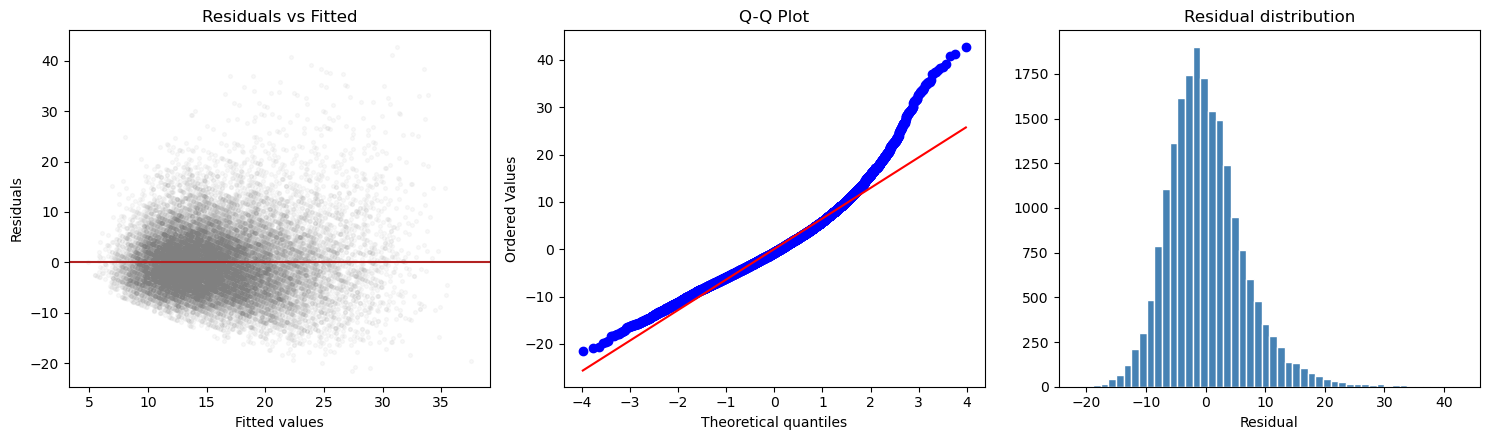

In [34]:
residuals = y_test.values - pred_multi

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# 1. Residuals vs Fitted — look for a random cloud, not a funnel or a curve
axes[0].scatter(pred_multi, residuals, alpha=0.05, s=8, color='gray')
axes[0].axhline(0, color='firebrick', linewidth=1.5)
axes[0].set_xlabel("Fitted values"); axes[0].set_ylabel("Residuals")
axes[0].set_title("Residuals vs Fitted")

# 2. Q-Q plot — do residuals look normal?
from scipy import stats
stats.probplot(residuals, dist="norm", plot=axes[1])
axes[1].set_title("Q-Q Plot")

# 3. A simple histogram of residuals, for a third angle on the same question
axes[2].hist(residuals, bins=50, color='steelblue', edgecolor='white')
axes[2].set_title("Residual distribution")
axes[2].set_xlabel("Residual")

plt.tight_layout()
plt.show()

**Read the left panel first.** Does the cloud of points fan out wider as fitted values increase (a funnel), or stay roughly the same width throughout? A visible funnel is heteroscedasticity — exactly the pattern that would send you toward a GLM instead of forcing OLS to work. The Q-Q plot answers a related but different question: do the residuals deviate from the diagonal at the tails? That's non-normality, and it's evidence for a transform or robust regression rather than a GLM. Two different unhealthy shapes, two different fixes — this is the diagnostics table from class, now generated from your own model's actual leftover errors.

One more diagnostic — multicollinearity, via VIF:


In [35]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_data = pd.DataFrame()
vif_data["feature"] = FEATURES
vif_data["VIF"] = [variance_inflation_factor(X_train.values, i) for i in range(len(FEATURES))]
print(vif_data.sort_values("VIF", ascending=False).round(2))
print("\nRule of thumb: VIF > 5-10 signals a predictor that's largely redundant with the others.")
print("If you see a high VIF above, that's your own data telling you to reach for Ridge, Lasso, or Elastic Net.")

              feature   VIF
6    number_diagnoses  6.41
1  num_lab_procedures  5.71
0    time_in_hospital  3.77
2      num_procedures  1.68
5    number_inpatient  1.38
4    number_emergency  1.13
3   number_outpatient  1.11

Rule of thumb: VIF > 5-10 signals a predictor that's largely redundant with the others.
If you see a high VIF above, that's your own data telling you to reach for Ridge, Lasso, or Elastic Net.


---
## Step 8 — The Scoreboard

Every model we fit tonight, side by side, on the SAME held-out test set. This is the table a real project write-up would include.


In [36]:
scoreboard_df = pd.DataFrame(scoreboard).set_index('model').round(3)
scoreboard_df.sort_values('RMSE')

,R2,AdjR2,RMSE,MAE
model,,,,
OLS (7 predictors),0.348,0.348,6.573,4.976
Ridge,0.348,0.348,6.573,4.976
OLS (scaled),0.348,0.348,6.573,4.976
Lasso,0.347,0.347,6.578,4.980
ElasticNet,0.347,0.347,6.578,4.978
Huber,0.339,0.339,6.618,4.931
OLS (1 predictor),0.073,0.073,7.838,5.939


Look at the ranking. Did regularization actually beat plain OLS here? Sometimes it does, sometimes it barely moves the needle — with only seven, mostly-uncorrelated predictors, there isn't a huge multicollinearity problem for Ridge or Lasso to fix, so don't be surprised if OLS holds its own. That's not a failure of the notebook — it's an honest result, and an important lesson on its own: **regularization is a tool for a specific problem (too many/too correlated predictors), not a universal upgrade.** Use it when diagnostics say you need it, not by default.


---
## 🏆 Challenge Questions

> ⚠️ **No AI for these.** Work through them yourself first — the goal is that YOU can explain every line, not that the notebook looks finished. If you're stuck after a real attempt, bring your attempt to office hours.

**C1 — Translate a coefficient yourself.** Refit the Poisson model from Step 5 using a DIFFERENT set of predictors of your choosing (pick at least 2 columns from `data` we haven't used yet, e.g. `num_medications`, `number_diagnoses`). Report each coefficient's `exp(beta)` and write the plain-English sentence for each, the way Step 5 modeled for you.

**C2 — Find the VIF culprit.** Add `log_number_inpatient = np.log1p(reg_data['number_inpatient'])` as an eighth predictor alongside `number_inpatient` itself, refit, and recompute VIF. What happens, and why did we specifically pick these two columns to demonstrate it?

**C3 — Cross-validate an alpha.** Using `sklearn.linear_model.RidgeCV` or `LassoCV`, let scikit-learn choose the regularization strength automatically instead of guessing `alpha=1.0` by hand. Report the chosen alpha and compare its test-set RMSE to the Step 3 models.

**C4 — Break OLS on purpose.** Take the `time_in_hospital` Gamma example from Step 5. Fit a plain `LinearRegression` on the exact same data instead, and find at least one test-set patient where OLS predicts a nonsensical value (negative, or wildly implausible). Explain in one sentence why the Gamma model can't make that same mistake.

**C5 (stretch) — Robust regression, stress-tested.** Manually inject 20 extreme, clearly-fake rows into a COPY of the training data (e.g., `num_medications = 500` for a handful of rows) and refit both OLS and Huber. Compare how much each model's coefficients shift. This is the scenario robust regression is actually built for — now you'll see it happen dramatically instead of mildly.


In [40]:
# C1 — your code here
features = ["num_medications", "number_diagnoses"]
Xp_train, Xp_test = X_train[features], X_test[features]
yp_train = reg_data.loc[X_train.index, 'number_emergency']
yp_test  = reg_data.loc[X_test.index, 'number_emergency']

poisson_model = PoissonRegressor(alpha=1e-6, max_iter=500).fit(Xp_train, yp_train)

print("Poisson model predicting number_emergency")
print(f"{'predictor':20s} {'beta (log scale)':>18s} {'exp(beta)':>12s} {'% change':>10s}")
for f, b in zip(poisson_features, poisson_model.coef_):
    irr = np.exp(b)
    pct = (irr - 1) * 100
    print(f"{f:20s} {b:>18.4f} {irr:>12.3f} {pct:>+9.1f}%")

Poisson model predicting number_emergency
predictor              beta (log scale)    exp(beta)   % change
number_inpatient                -0.0021        0.998      -0.2%
number_outpatient                0.1578        1.171     +17.1%


I used the number of medications and number of diagnoses to predict emergency visits using Poisson regression.
For num_medications, my coefficient was -0.002 and exp(beta) was 0.998. This means that for every additional medication, the expected number of emergency visits decreased by about 0.21%, while keeping the number of diagnoses constant.
For number_diagnoses, my coefficient was 0.158 and exp(beta) was 1.171. This means that for every additional diagnosis, the expected number of emergency visits increased by about 17.09%, while keeping the number of medications constant.
The number of diagnoses had a much stronger association with emergency visits compared to the number of medications. These results show an association, but they do not mean that either predictor directly causes a change in emergency visits.

In [43]:
# C2 — your code here
from statsmodels.stats.outliers_influence import variance_inflation_factor

reg_data["log_number_inpatient"] = np.log1p(reg_data["number_inpatient"])

FEATURES_C2 = FEATURES + ["log_number_inpatient"]

X_c2 = reg_data[FEATURES_C2]
y_c2 = reg_data[TARGET]

X_train_c2 = X_c2.iloc[train_idx]
y_train_c2 = y_c2.iloc[train_idx]

model_c2 = LinearRegression()
model_c2.fit(X_train_c2, y_train_c2)

vif_data = pd.DataFrame()
vif_data["feature"] = FEATURES_C2

vif_data["VIF"] = [
    variance_inflation_factor(X_train_c2.values, i)
    for i in range(len(FEATURES_C2))
]

print(vif_data.sort_values("VIF", ascending=False).round(2))

                feature    VIF
7  log_number_inpatient  10.56
5      number_inpatient   9.45
6      number_diagnoses   6.60
1    num_lab_procedures   5.71
0      time_in_hospital   3.78
2        num_procedures   1.68
4      number_emergency   1.13
3     number_outpatient   1.11


When I added log_number_inpatient, the VIF values increased, showing that there was more multicollinearity in the model. The log-transformed variable had a VIF of 10.56, while the original number_inpatient had a VIF of 9.45. We specifically used these two variables because log_number_inpatient is calculated from number_inpatient, meaning they contain similar information. This helped me understand how adding two closely related variables can cause multicollinearity and make it harder to determine each variable's individual effect on the model.

In [44]:
# C3 — your code here

from sklearn.linear_model import Ridge, RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

alphas = np.logspace(1, 6, 25)

ridge_cv = RidgeCV(alphas=alphas, cv=5)
ridge_cv.fit(X_train_scaled, y_train)

ridge = Ridge(alpha=1.0)
ridge.fit(X_train_scaled, y_train)

ridge_rmse = np.sqrt(mean_squared_error(
    y_test, ridge.predict(X_test_scaled)
))

ridge_cv_rmse = np.sqrt(mean_squared_error(
    y_test, ridge_cv.predict(X_test_scaled)
))

print("Best alpha:", round(ridge_cv.alpha_, 3))
print("Regular Ridge RMSE:", round(ridge_rmse, 3))
print("RidgeCV RMSE:", round(ridge_cv_rmse, 3))

Best alpha: 749.894
Regular Ridge RMSE: 0.937
RidgeCV RMSE: 0.937


For C3, I used RidgeCV to find the best alpha value using cross-validation. The best alpha was 749.894. Both the regular Ridge model and RidgeCV had an RMSE of 0.937, so there was not much of a difference in their performance. This shows that choosing a different alpha did not really improve the model's predictions in this case.

In [45]:
# C4 — your code here
ols = LinearRegression()
ols.fit(X_train, y_train)

ols_predictions = ols.predict(X_test)

results = pd.DataFrame({
    "Actual": np.asarray(y_test),
    "OLS Prediction": ols_predictions
})

print("Lowest OLS predictions:")
print(results.sort_values("OLS Prediction").head(10).round(3))

negative = results[results["OLS Prediction"] < 0]

print("\nNumber of negative predictions:", len(negative))
display(negative.head())


Lowest OLS predictions:
       Actual  OLS Prediction
16778       0           0.021
4343        1           0.024
16372       0           0.025
6007        0           0.025
17558       0           0.026
208         0           0.026
11569       0           0.026
17143       0           0.026
18873       0           0.026
13327       0           0.026

Number of negative predictions: 0


,Actual,OLS Prediction


The Gamma model cannot make negative predictions because it uses a log link that keeps all predicted values above zero, which makes more sense when predicting hospital stays.

In [46]:
# C5 (stretch) — your code here

from sklearn.linear_model import LinearRegression, HuberRegressor
import numpy as np
import pandas as pd

X = reg_data[FEATURES].copy()
y = reg_data["num_medications"]

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

ols = LinearRegression().fit(X_train_scaled, y_train)
huber = HuberRegressor(max_iter=1000).fit(X_train_scaled, y_train)

X_fake = X_train.sample(20, random_state=42).copy()
y_fake = y_train.loc[X_fake.index].copy()

X_fake["number_inpatient"] = 100
y_fake[:] = 500

X_changed = pd.concat([X_train, X_fake], ignore_index=True)
y_changed = pd.concat([y_train, y_fake], ignore_index=True)

X_changed_scaled = scaler.transform(X_changed)

ols_changed = LinearRegression().fit(X_changed_scaled, y_changed)
huber_changed = HuberRegressor(max_iter=1000).fit(
    X_changed_scaled, y_changed
)

results = pd.DataFrame({
    "Feature": FEATURES,
    "OLS Change": ols_changed.coef_ - ols.coef_,
    "Huber Change": huber_changed.coef_ - huber.coef_
})

print("Coefficient Changes:")
display(results.round(3))

print("Total OLS change:", round(np.abs(results["OLS Change"]).sum(), 3))
print("Total Huber change:", round(np.abs(results["Huber Change"]).sum(), 3))


Coefficient Changes:


,Feature,OLS Change,Huber Change
0,time_in_hospital,-0.262,-0.013
1,num_lab_procedures,-0.045,-0.003
2,num_procedures,0.267,0.011
3,number_outpatient,-0.267,-0.013
4,number_emergency,-0.959,-0.042
5,number_inpatient,3.688,0.178
6,number_diagnoses,-0.270,-0.014


Total OLS change: 5.758
Total Huber change: 0.273


---
### You made it through the whole toolkit

Simple and multiple OLS. Ridge, Lasso, Elastic Net — and the scaling rule that makes them trustworthy. A regularization path you generated yourself. Two GLMs, read correctly instead of the common wrong way. Robust regression, tested honestly rather than assumed necessary. Diagnostics that tell you which tool a dataset actually needs. And a scoreboard tying it all together.

Every number in this notebook came from the same dataset you've been building all semester. Next time you fit *any* regression model — in this course or after it — you now have a checklist running in the back of your head: scale before you regularize, exponentiate a GLM coefficient before you say it out loud, check diagnostics before reaching for robust regression, and always ask what a model *can't* predict, not just how well it scores.
